# Clasificador de imágenes: perros y gatos

Proyecto del módulo «Modelos de clasificación» de 4Geeks (*Proyecto Tutorial de Clasificador de Imágenes*).

Objetivos del enunciado:

- Comprender un dataset nuevo.
- Modelar los datos con una red neuronal artificial.
- Analizar los resultados y optimizar el modelo.

El dataset es el de Asirra (Petfinder.com y Microsoft): 25.000 fotos de perros y gatos etiquetadas por el nombre del archivo. Como referencia, el enunciado cita un SVM de 2007 que llegó al 80 % de precisión.

In [1]:
import os
import time
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
import keras
from keras.applications import EfficientNetB0
from keras.models import Sequential
from keras.layers import Dense, GlobalAveragePooling2D, Input, RandomFlip, RandomRotation
from keras.callbacks import ModelCheckpoint, EarlyStopping

# tf.data ya baraja el train; Keras avisa igualmente de que ignora su propio shuffle
warnings.filterwarnings("ignore", message="`shuffle=True` was passed")

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
SEED = 42
IMG_SIZE = 200          # tamaño fijo que pide el enunciado (200x200)
BATCH_SIZE = 32
CLASSES = ["cat", "dog"]  # índice 0 = gato, 1 = perro

ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
TRAIN_DIR = ROOT / "data" / "raw" / "dogs-vs-cats" / "train"
INTERIM = ROOT / "data" / "interim"
MODELS = ROOT / "models"
INTERIM.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

keras.utils.set_random_seed(SEED)

## Paso 1: carga del conjunto de datos

El zip del enunciado (`dogs-vs-cats.zip`) se descomprime en `data/raw/`. Dentro está la carpeta `train` con los `.jpg`; la etiqueta es la primera palabra del nombre (`cat.123.jpg`, `dog.456.jpg`).

In [3]:
files = sorted(TRAIN_DIR.glob("*.jpg"))
df = pd.DataFrame({"path": files})
df["label"] = df["path"].map(lambda p: p.name.split(".")[0])
print(f"{len(df)} imágenes")
df["label"].value_counts()

25000 imágenes


label
cat    12500
dog    12500
Name: count, dtype: int64

In [4]:
assert set(df["label"]) == set(CLASSES), "hay archivos con una etiqueta inesperada"

## Paso 2: visualización de la información de entrada

Las nueve primeras fotos de cada clase, con su tamaño original.

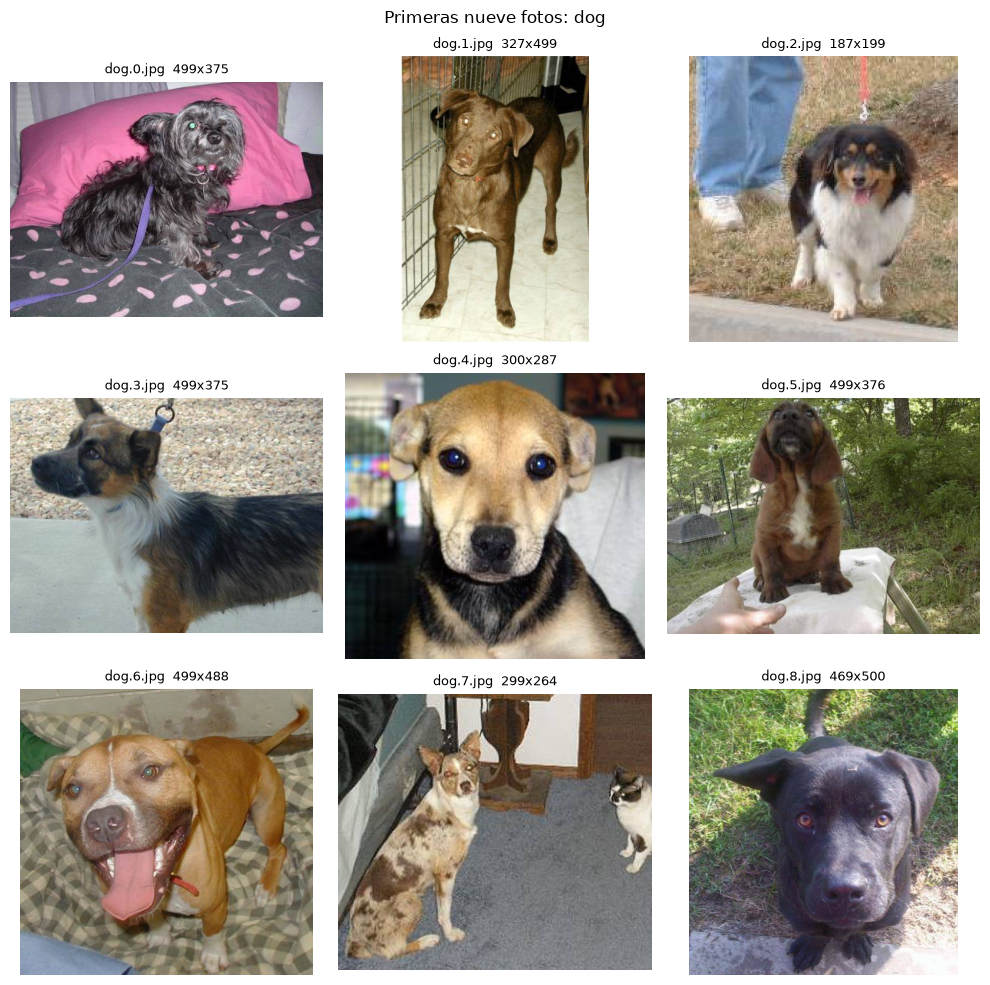

In [5]:
def show_first_nine(label):
    paths = sorted(df.loc[df["label"] == label, "path"], key=lambda p: int(p.name.split(".")[1]))[:9]
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    for ax, path in zip(axes.flat, paths):
        img = keras.utils.load_img(path)
        ax.imshow(img)
        ax.set_title(f"{path.name}  {img.size[0]}x{img.size[1]}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"Primeras nueve fotos: {label}")
    plt.tight_layout()
    plt.show()

show_first_nine("dog")

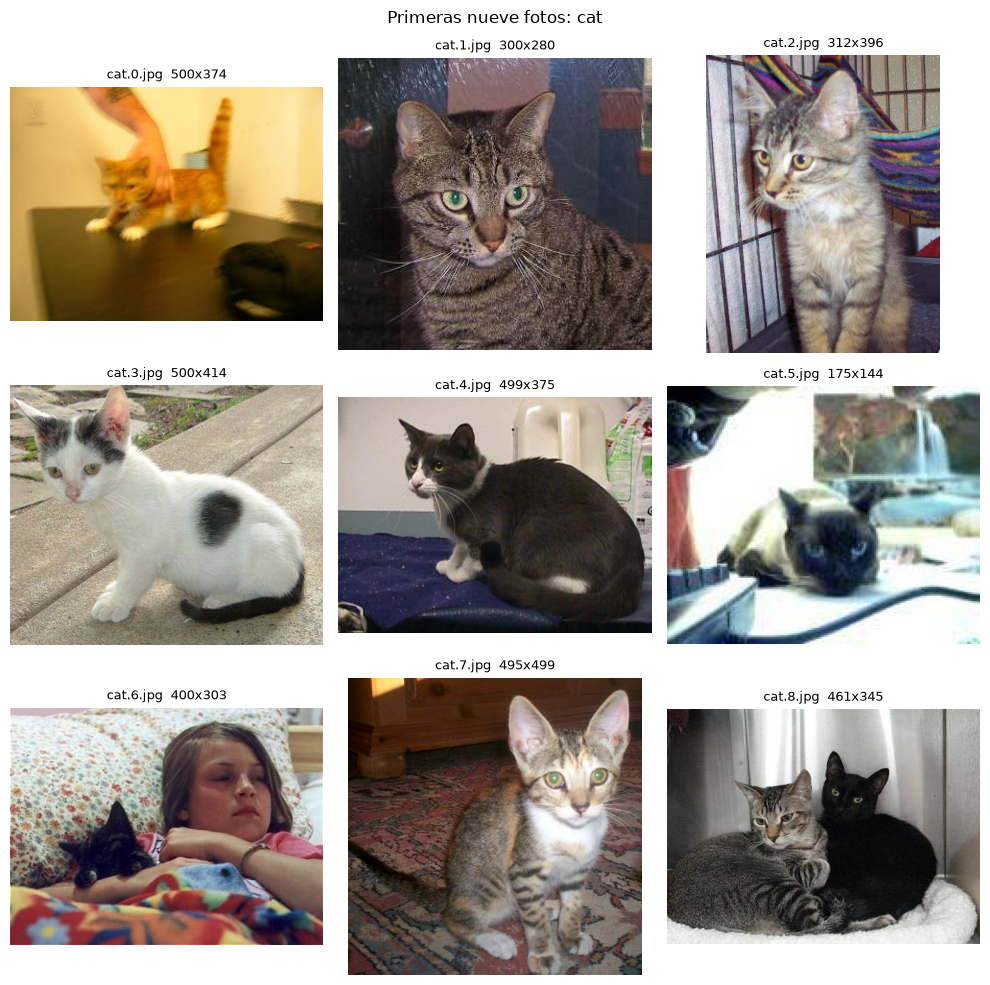

In [6]:
show_first_nine("cat")

Las fotos son en color y cada una tiene un tamaño distinto. Leemos solo la cabecera de cada archivo para ver la variedad completa sin cargar los píxeles.

In [7]:
def header_info(path):
    with Image.open(path) as im:
        return im.size[0], im.size[1], im.mode

with ThreadPoolExecutor(max_workers=16) as pool:
    info = list(pool.map(header_info, df["path"]))
df[["width", "height", "mode"]] = pd.DataFrame(info, index=df.index)

print(df["mode"].value_counts().to_string())
df[["width", "height"]].describe().round(1)

mode
RGB    25000


,width,height
count,25000.0,25000.0
mean,404.1,360.5
std,109.0,97.0
min,42.0,32.0
25%,323.0,301.0
50%,447.0,374.0
75%,499.0,421.0
max,1050.0,768.0


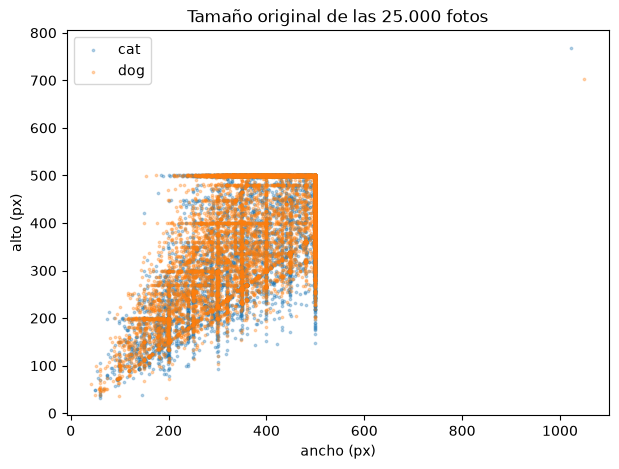

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for label, part in df.groupby("label"):
    ax.scatter(part["width"], part["height"], s=3, alpha=0.3, label=label)
ax.set_xlabel("ancho (px)")
ax.set_ylabel("alto (px)")
ax.set_title("Tamaño original de las 25.000 fotos")
ax.legend()
plt.show()

Casi todas miden como mucho 500 px por lado, pero con proporciones muy distintas. Antes de entrenar las llevamos todas a 200x200.

**Qué regla aplicamos.** El enunciado da dos caminos según la RAM. Con más de 12 GB se cargan las 25.000 fotos en memoria con la API de imágenes de Keras y se guarda una tupla (fotos, etiquetas). Con menos se cargan poco a poco con `ImageDataGenerator` y `flow_from_directory()`. Esta máquina tiene más de 12 GB, así que seguimos la primera regla. En `uint8`, 25.000 × 200 × 200 × 3 ocupa unos 3 GB.

`ImageDataGenerator` ya no existe en Keras 3.15. Si hiciera falta el camino de poca RAM, su equivalente actual es `keras.utils.image_dataset_from_directory`.

In [9]:
total_ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
print(f"RAM total: {total_ram_gb:.1f} GB")
assert total_ram_gb > 12, "con 12 GB o menos hay que cargar las imágenes de forma progresiva"

RAM total: 23.5 GB


In [10]:
CACHE = INTERIM / f"dogs_vs_cats_{IMG_SIZE}.npz"

def load_resized(path):
    img = keras.utils.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))  # convierte a RGB y redimensiona
    return keras.utils.img_to_array(img, dtype="uint8")

if CACHE.exists():
    with np.load(CACHE) as data:
        photos, labels = data["photos"], data["labels"]
else:
    start = time.time()
    with ThreadPoolExecutor(max_workers=16) as pool:
        photos = np.stack(list(pool.map(load_resized, df["path"])))
    labels = df["label"].map(CLASSES.index).to_numpy(dtype="uint8")
    np.savez(CACHE, photos=photos, labels=labels)  # la tupla (fotos, etiquetas) que pide el enunciado
    print(f"Cargadas en {time.time() - start:.0f} s")

print(photos.shape, photos.dtype, f"{photos.nbytes / 1024**3:.2f} GB")
print("etiquetas:", np.bincount(labels), "(0 = cat, 1 = dog)")

Cargadas en 32 s
(25000, 200, 200, 3) uint8 2.79 GB
etiquetas: [12500 12500] (0 = cat, 1 = dog)


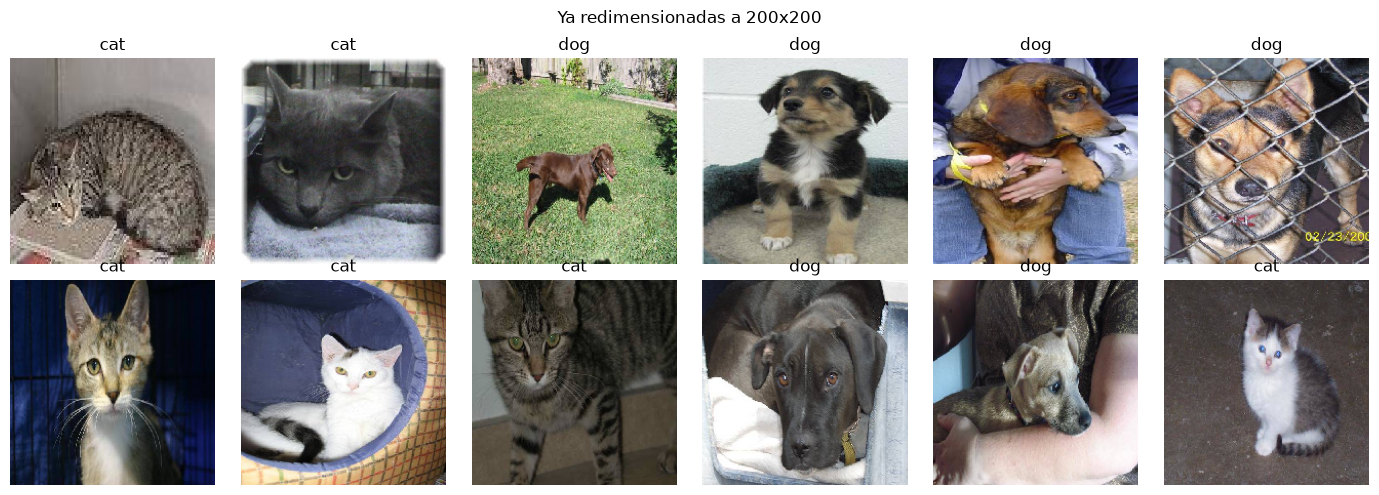

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.flat, np.random.default_rng(SEED).choice(len(photos), 12, replace=False)):
    ax.imshow(photos[i])
    ax.set_title(CLASSES[labels[i]])
    ax.axis("off")
fig.suptitle("Ya redimensionadas a 200x200")
plt.tight_layout()
plt.show()

### Conjuntos de entrenamiento, validación y test

Solo la carpeta `train` tiene etiquetas, así que el test sale de ella. Dividimos 70 / 15 / 15, estratificado por clase:

- **train**: entrena la red.
- **validación**: la vigilan los callbacks del paso 4.
- **test**: no se toca hasta la evaluación final.

El enunciado llama `trdata` y `tsdata` a los objetos de entrenamiento y test. Aquí son `tf.data.Dataset` construidos desde los arrays en memoria. La red termina en `softmax` con 2 unidades, así que las etiquetas van en one-hot.

No normalizamos los píxeles: las EfficientNet de Keras incluyen el reescalado dentro del modelo y esperan valores 0-255.

In [12]:
idx = np.arange(len(labels))
idx_train, idx_rest = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.50, stratify=labels[idx_rest], random_state=SEED)

x_train, y_train = photos[idx_train], labels[idx_train]
x_val, y_val = photos[idx_val], labels[idx_val]
x_test, y_test = photos[idx_test], labels[idx_test]
del photos  # liberamos la copia completa
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} {len(y):6d}  gatos={np.sum(y == 0)}  perros={np.sum(y == 1)}")

train  17500  gatos=8750  perros=8750
val     3750  gatos=1875  perros=1875
test    3750  gatos=1875  perros=1875


In [13]:
def make_dataset(x, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x, keras.utils.to_categorical(y, 2)))
    if shuffle:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).map(lambda a, b: (tf.cast(a, tf.float32), b)).prefetch(tf.data.AUTOTUNE)

trdata = make_dataset(x_train, y_train, shuffle=True)
valdata = make_dataset(x_val, y_val)
tsdata = make_dataset(x_test, y_test)

## Paso 3: construcción de la RNA

La arquitectura de prueba del enunciado es la backbone convolucional de EfficientNet-B0 sin pesos (`weights = None`), un `GlobalAveragePooling2D` y dos capas `Dense`, la última con 2 salidas `softmax`.

El enunciado se contradice en un punto: el paso 2 fija las imágenes en 200x200 y la arquitectura declara `input_shape = (224, 224, 3)`. Usamos 200x200. EfficientNet-B0 sin la cabeza de clasificación acepta cualquier tamaño a partir de 32 px, y así las imágenes no se redimensionan dos veces.

Completamos el modelo con el optimizador Adam (tasa de aprendizaje 0,001), pérdida `categorical_crossentropy` y métrica `accuracy`.

In [14]:
def build_model(weights):
    model = Sequential(name=f"efficientnet_b0_{weights or 'scratch'}")
    model.add(EfficientNetB0(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3)))
    model.add(GlobalAveragePooling2D())
    model.add(Dense(units=128, activation="relu"))
    model.add(Dense(units=2, activation="softmax"))
    return model

baseline = build_model(weights=None)
baseline.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                 loss="categorical_crossentropy", metrics=["accuracy"])
baseline.summary()

Model: "efficientnet_b0_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

**Presupuesto de entrenamiento.** Entrenamos en CPU, sin GPU. Medimos unas 22 imágenes/s para EfficientNet-B0 desde cero, así que una pasada completa por las 17.500 fotos de train tarda unos 13 minutos. Al modelo base le damos 4 épocas de 150 lotes (4.800 fotos por época, unas 19.200 en total). Basta para ver si los pesos aleatorios aprenden algo; no es un entrenamiento completo.

In [15]:
BASELINE_EPOCHS = 4
BASELINE_STEPS = 150

start = time.time()
hist_base = baseline.fit(trdata.repeat(), epochs=BASELINE_EPOCHS, steps_per_epoch=BASELINE_STEPS,
                         validation_data=valdata, verbose=2)
print(f"Entrenamiento: {(time.time() - start) / 60:.1f} min")

Epoch 1/4


150/150 - 240s - 2s/step - accuracy: 0.5821 - loss: 0.7238 - val_accuracy: 0.5000 - val_loss: 0.7249


Epoch 2/4


150/150 - 225s - 1s/step - accuracy: 0.6310 - loss: 0.6476 - val_accuracy: 0.5000 - val_loss: 0.8747


Epoch 3/4


150/150 - 270s - 2s/step - accuracy: 0.6627 - loss: 0.6164 - val_accuracy: 0.6149 - val_loss: 0.6895


Epoch 4/4


150/150 - 236s - 2s/step - accuracy: 0.7152 - loss: 0.5645 - val_accuracy: 0.7259 - val_loss: 0.5475


Entrenamiento: 16.2 min


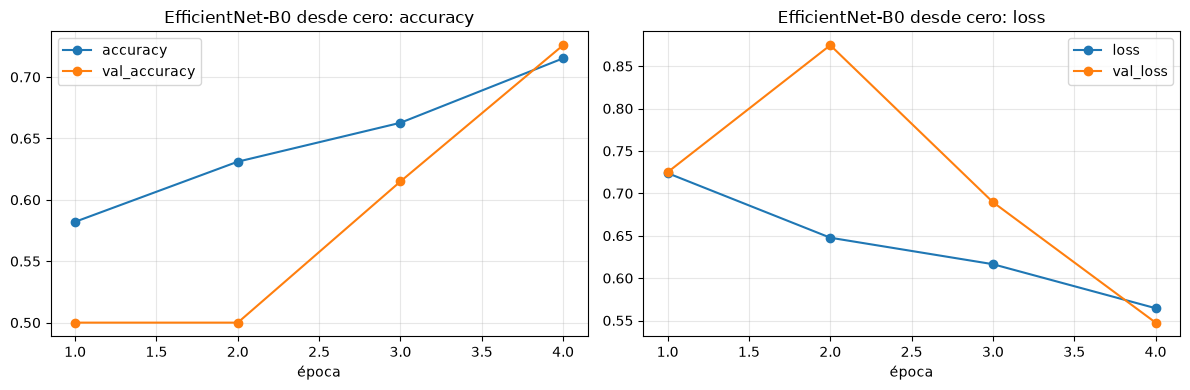

,accuracy,loss,val_accuracy,val_loss
1,0.5821,0.7238,0.5000,0.7249
2,0.6310,0.6476,0.5000,0.8747
3,0.6627,0.6164,0.6149,0.6895
4,0.7152,0.5645,0.7259,0.5475


In [16]:
def plot_history(hist, title):
    h = pd.DataFrame(hist.history)
    h.index = h.index + 1
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    h[["accuracy", "val_accuracy"]].plot(ax=a1, marker="o", title=f"{title}: accuracy")
    h[["loss", "val_loss"]].plot(ax=a2, marker="o", title=f"{title}: loss")
    for a in (a1, a2):
        a.set_xlabel("época")
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return h.round(4)

plot_history(hist_base, "EfficientNet-B0 desde cero")

In [17]:
base_val_loss, base_val_acc = baseline.evaluate(valdata, verbose=0)
print(f"Modelo base, validación: accuracy={base_val_acc:.4f}  loss={base_val_loss:.4f}")

Modelo base, validación: accuracy=0.7259  loss=0.5475


## Paso 4: optimización del modelo

El enunciado pide crear un `ModelCheckpoint` y un `EarlyStopping` y pasarlos como callbacks a `fit_generator`. En Keras 3 `fit_generator` ya no existe: `fit` acepta directamente el `tf.data.Dataset`.

- `ModelCheckpoint` guarda en `models/` el modelo con mejor `val_accuracy`.
- `EarlyStopping` corta el entrenamiento si `val_accuracy` no mejora en 3 épocas.

Tras ver unas 19.000 fotos, el modelo desde cero se queda en un 72,6 % en validación, por debajo del 80 % del SVM de 2007. Sigue mejorando de una época a otra, pero con pesos aleatorios necesita muchas más épocas para acercarse a un buen resultado, y en CPU son horas. La mejora con más efecto es arrancar la misma arquitectura con los pesos de ImageNet (`weights = "imagenet"`), donde ya ha aprendido bordes, texturas y formas de animales. Congelamos la backbone y entrenamos solo la cabeza densa. Además añadimos volteo horizontal y una rotación pequeña como aumento de datos, porque hay fotos con el animal en una esquina o torcido. Estas dos capas solo actúan durante el entrenamiento.

In [18]:
backbone = EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
backbone.trainable = False

optimized = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    RandomFlip("horizontal", seed=SEED),
    RandomRotation(0.05, seed=SEED),
    backbone,
    GlobalAveragePooling2D(),
    Dense(units=128, activation="relu"),
    Dense(units=2, activation="softmax"),
], name="efficientnet_b0_imagenet")
optimized.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="categorical_crossentropy", metrics=["accuracy"])
optimized.summary()

Model: "efficientnet_b0_imagenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 200, 200, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [19]:
BEST_MODEL = MODELS / "efficientnet_b0_imagenet.keras"

checkpoint = ModelCheckpoint(BEST_MODEL, monitor="val_accuracy", mode="max", save_best_only=True, verbose=1)
early = EarlyStopping(monitor="val_accuracy", mode="max", patience=3, verbose=1)

start = time.time()
hist_opt = optimized.fit(trdata, epochs=12, validation_data=valdata, callbacks=[checkpoint, early], verbose=2)
print(f"Entrenamiento: {(time.time() - start) / 60:.1f} min, {len(hist_opt.history['loss'])} épocas")

Epoch 1/12



Epoch 1: val_accuracy improved from None to 0.98907, saving model to /home/pau/pau/paura432-image-classifier/models/efficientnet_b0_imagenet.keras



Epoch 1: finished saving model to /home/pau/pau/paura432-image-classifier/models/efficientnet_b0_imagenet.keras


547/547 - 170s - 310ms/step - accuracy: 0.9831 - loss: 0.0482 - val_accuracy: 0.9891 - val_loss: 0.0313


Epoch 2/12



Epoch 2: val_accuracy did not improve from 0.98907


... (12 outputs left out)


Epoch 6: val_accuracy did not improve from 0.99173


547/547 - 140s - 256ms/step - accuracy: 0.9950 - loss: 0.0145 - val_accuracy: 0.9909 - val_loss: 0.0365


Epoch 6: early stopping


Entrenamiento: 16.6 min, 6 épocas


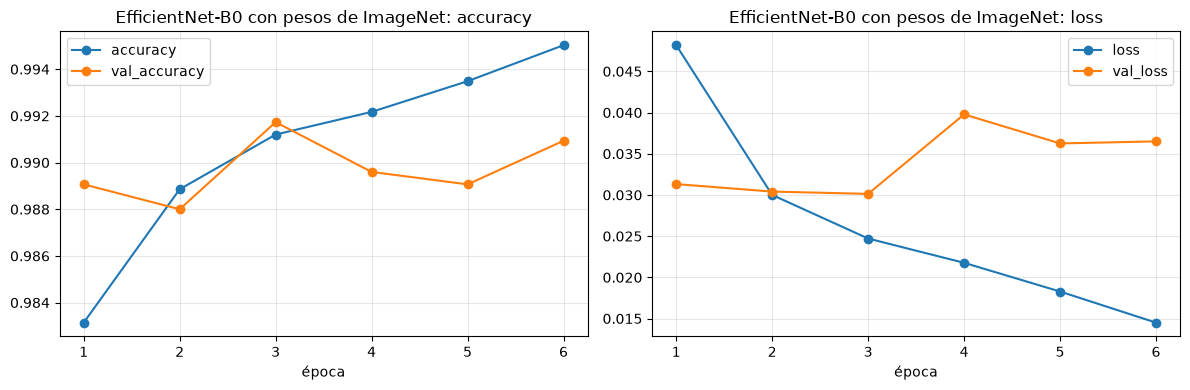

,accuracy,loss,val_accuracy,val_loss
1,0.9831,0.0482,0.9891,0.0313
2,0.9889,0.0300,0.9880,0.0304
3,0.9912,0.0247,0.9917,0.0301
4,0.9922,0.0218,0.9896,0.0398
5,0.9935,0.0183,0.9891,0.0363
6,0.9950,0.0145,0.9909,0.0365


In [20]:
plot_history(hist_opt, "EfficientNet-B0 con pesos de ImageNet")

### Predicciones sobre el test con el mejor modelo

Cargamos el mejor modelo desde el archivo que guardó `ModelCheckpoint` y predecimos sobre las 3.750 fotos de test, que ningún modelo ha visto. Evaluamos también el modelo base sobre el mismo test.

In [21]:
best = keras.models.load_model(BEST_MODEL)

proba_best = best.predict(tsdata, verbose=0)
pred_best = proba_best.argmax(axis=1)
pred_base = baseline.predict(tsdata, verbose=0).argmax(axis=1)

summary = pd.DataFrame({
    "modelo": ["EfficientNet-B0 desde cero (paso 3)", "EfficientNet-B0 ImageNet + callbacks (paso 4)"],
    "accuracy_test": [np.mean(pred_base == y_test), np.mean(pred_best == y_test)],
}).round(4)
summary

,modelo,accuracy_test
0,EfficientNet-B0 desde cero (paso 3),0.7277
1,EfficientNet-B0 ImageNet + callbacks (paso 4),0.9917


              precision    recall  f1-score   support

         cat     0.9904    0.9931    0.9917      1875
         dog     0.9930    0.9904    0.9917      1875

    accuracy                         0.9917      3750
   macro avg     0.9917    0.9917    0.9917      3750
weighted avg     0.9917    0.9917    0.9917      3750



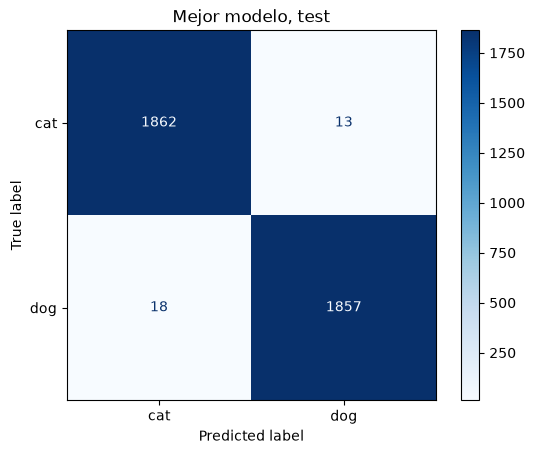

In [22]:
print(classification_report(y_test, pred_best, target_names=CLASSES, digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_best), display_labels=CLASSES).plot(cmap="Blues")
plt.title("Mejor modelo, test")
plt.show()

Fotos de test que el mejor modelo clasifica mal, empezando por las que falla con más confianza:

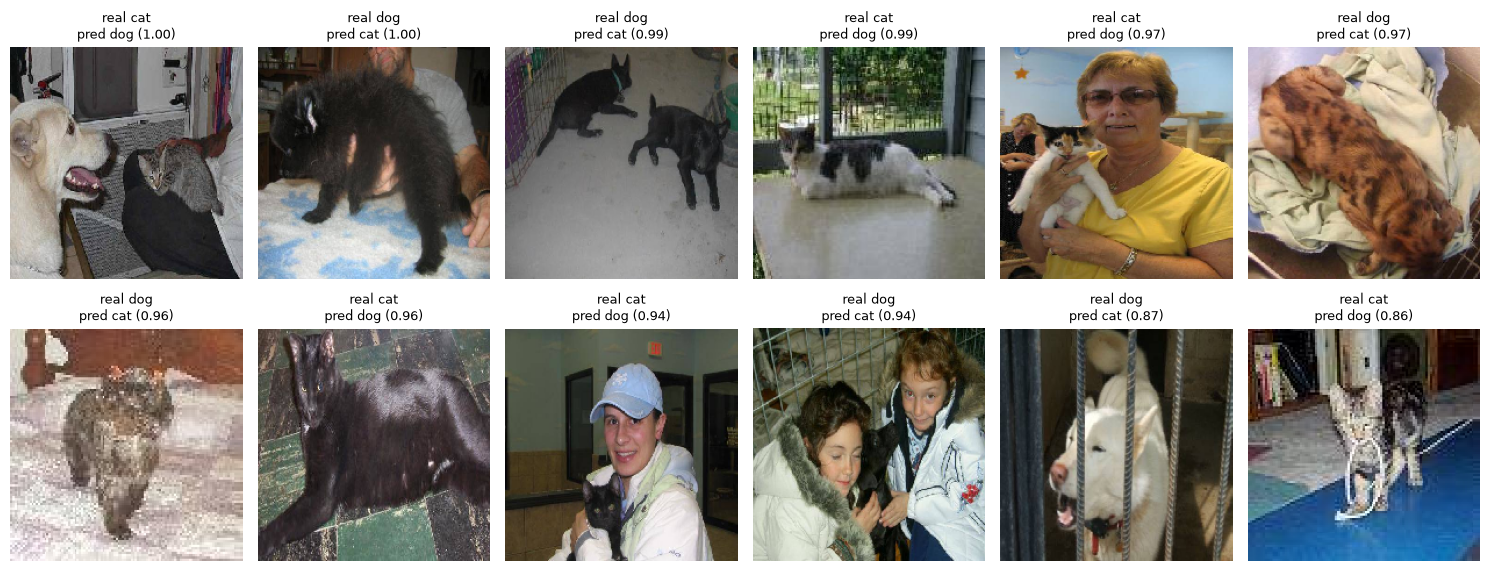

31 errores de 3750


In [23]:
wrong = np.flatnonzero(pred_best != y_test)
wrong = wrong[np.argsort(-proba_best[wrong].max(axis=1))][:12]
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(x_test[i])
    ax.set_title(f"real {CLASSES[y_test[i]]}\npred {CLASSES[pred_best[i]]} ({proba_best[i].max():.2f})", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(wrong):]:
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"{len(np.flatnonzero(pred_best != y_test))} errores de {len(y_test)}")

## Paso 5: guardado del modelo

`ModelCheckpoint` ya ha guardado el mejor modelo en `models/efficientnet_b0_imagenet.keras`, en el formato nativo de Keras 3, que incluye la arquitectura y los pesos. Comprobamos que el archivo funciona por sí solo: lo cargamos de nuevo, clasificamos una foto leída directamente del disco y miramos que las predicciones del test coinciden con las de antes.

El modelo base desde cero no se guarda. Su precisión es muy inferior y ocuparía otros 50 MB en el repositorio.

In [24]:
reloaded = keras.models.load_model(BEST_MODEL)
assert np.array_equal(reloaded.predict(tsdata, verbose=0).argmax(axis=1), pred_best)

sample = df.loc[idx_test[0], "path"]
img = keras.utils.img_to_array(keras.utils.load_img(sample, target_size=(IMG_SIZE, IMG_SIZE)))
proba = reloaded.predict(img[None, ...], verbose=0)[0]
print(f"{sample.name}: {CLASSES[proba.argmax()]} ({proba.max():.2%})")
print(f"{BEST_MODEL.relative_to(ROOT)}: {BEST_MODEL.stat().st_size / 1024**2:.1f} MB")

dog.8635.jpg: dog (99.98%)
models/efficientnet_b0_imagenet.keras: 18.1 MB


## Conclusiones

| Modelo | Entrenamiento | Accuracy en test |
| --- | --- | --- |
| EfficientNet-B0 desde cero (paso 3) | 4 épocas de 150 lotes, 16 min | 72,8 % |
| EfficientNet-B0 con ImageNet, backbone congelada, `ModelCheckpoint` + `EarlyStopping` (paso 4) | 6 épocas completas, 17 min | 99,2 % |

- La arquitectura que propone el enunciado funciona, pero con `weights = None` y un presupuesto de CPU de unos 16 minutos solo llega al 72,8 % en test, por debajo del 80 % que el enunciado atribuye al SVM de 2007. La curva de validación seguía subiendo, así que el modelo no estaba saturado; le faltaba entrenamiento.
- La misma arquitectura con los pesos de ImageNet supera el 98,9 % de validación desde la primera época. `EarlyStopping` paró en la sexta porque `val_accuracy` no mejoraba desde la tercera, y `ModelCheckpoint` se quedó con esa tercera época (99,17 % en validación). Sobre las 3.750 fotos de test acierta el 99,17 %, con 31 errores: 13 gatos clasificados como perro y 18 perros como gato.
- Los errores con más confianza coinciden con los casos difíciles que anticipa el enunciado: un perro y un gato en la misma foto, el animal pequeño en brazos de una persona o tras unos barrotes, y animales negros sobre fondos oscuros. Alguna etiqueta también parece dudosa a simple vista. A 200x200 se pierde detalle en las fotos donde el animal ocupa poca parte de la imagen.
- El modelo guardado (`models/efficientnet_b0_imagenet.keras`, 18 MB) se carga por sí solo y `src/app.py` lo usa para clasificar fotos sueltas.
- Siguientes pasos posibles: descongelar los últimos bloques de la backbone con una tasa de aprendizaje baja (*fine-tuning*) y entrenar a 224x224, el tamaño con el que se preentrenó EfficientNet-B0. Los dos piden GPU para tiempos razonables.
